In [1]:
!pip -q install exifread

In [2]:
import os, exifread

D = "/kaggle/input/datasets/fajersaeed/dup-pairs"

def _f(x):
    try: return float(x)
    except TypeError: return x.num / x.den

def to_deg(vals, ref):
    d, m, s = [_f(v) for v in vals.values]
    deg = d + m/60 + s/3600
    return -deg if str(ref) in ("S", "W") else deg

def read_gps(path):
    with open(path, "rb") as fh:
        tags = exifread.process_file(fh, details=False)
    try:
        lat = to_deg(tags["GPS GPSLatitude"], tags["GPS GPSLatitudeRef"])
        lon = to_deg(tags["GPS GPSLongitude"], tags["GPS GPSLongitudeRef"])
        return lat, lon
    except KeyError:
        return None

for f in sorted(os.listdir(D)):
    g = read_gps(os.path.join(D, f))
    print(f"{f:25s}", f"{g[0]:.5f}, {g[1]:.5f}" if g else "no GPS")

lc1(a).DNG                18.28040, 42.70032
lc1(b).DNG                18.28047, 42.70031
lc10(a).DNG               18.30782, 42.69053
lc10(b).DNG               18.30783, 42.69053
lc11(a).DNG               18.30789, 42.69051
lc11(b).DNG               18.30789, 42.69054
lc12(a).DNG               18.30895, 42.70966
lc12(b).DNG               18.30899, 42.70965
lc13(a).DNG               18.31071, 42.71173
lc13(b).DNG               18.31071, 42.71174
lc14(a).DNG               18.30841, 42.70916
lc14(b).DNG               18.30837, 42.70913
lc15(a).DNG               18.31123, 42.71500
lc15(bvo gps).PNG         no GPS
lc2(a).DNG                18.31690, 42.69823
lc2(b).DNG                18.31702, 42.69796
lc3(a).DNG                18.31999, 42.70314
lc3(b).DNG                18.31999, 42.70314
lc4(a).DNG                18.31980, 42.70298
lc4(b).DNG                18.31980, 42.70300
lc5(a).DNG                18.31644, 42.70166
lc5(b).DNG                18.31641, 42.70165
lc6(a).DNG            

In [3]:
!pip -q install ultralytics

In [4]:
import os, re, glob
from PIL import Image, ImageOps
from ultralytics import YOLO

D = "/kaggle/input/datasets/fajersaeed/dup-pairs"
W = glob.glob("/kaggle/input/**/run17_best_finetuned.pt", recursive=True)[0]
yolo = YOLO(W)
print(yolo.names)

info = {}   # اسم الصورة -> (رقم الضرر, a أو b)
for f in sorted(os.listdir(D)):
    m = re.match(r"(lc|loc)(\d+)\((\w)", f)
    if m:
        info[f] = (m.group(1) + m.group(2), m.group(3))
print(len(info), "صورة")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
{0: 'D00', 1: 'D10', 2: 'D20', 3: 'D40'}
60 صورة


In [5]:
def load_det(f):
    im = ImageOps.exif_transpose(Image.open(os.path.join(D, f))).convert("RGB")
    im.thumbnail((1600, 1600))
    return im

def detect(im):
    r = yolo.predict(im, conf=0.46, imgsz=640, iou=0.7, max_det=300, verbose=False)[0]
    dets = []
    for (x1, y1, x2, y2), c, k in zip(r.boxes.xyxy.tolist(), r.boxes.conf.tolist(), r.boxes.cls.tolist()):
        dets.append({"cls": yolo.names[int(k)], "x": x1, "y": y1, "w": x2-x1, "h": y2-y1, "conf": c})
    return dets

dets_all = {}
for f in info:
    dets_all[f] = detect(load_det(f))
    print(f"{f:22s}", len(dets_all[f]))

lc1(a).DNG             1
lc1(b).DNG             0
lc10(a).DNG            1
lc10(b).DNG            1
lc11(a).DNG            1
lc11(b).DNG            1
lc12(a).DNG            1
lc12(b).DNG            1
lc13(a).DNG            0
lc13(b).DNG            1
lc14(a).DNG            0
lc14(b).DNG            1
lc15(a).DNG            0
lc15(bvo gps).PNG      0
lc2(a).DNG             1
lc2(b).DNG             1
lc3(a).DNG             3
lc3(b).DNG             7
lc4(a).DNG             6
lc4(b).DNG             4
lc5(a).DNG             6
lc5(b).DNG             2
lc6(a).DNG             3
lc6(b).DNG             2
lc7(a).DNG             1
lc7(b).DNG             1
lc8(a).DNG             3
lc8(b).DNG             1
lc9(a).DNG             0
lc9(b).DNG             1
loc16(a).JPG           2
loc16(b).JPG           1
loc17(a).JPG           1
loc17(b).JPG           0
loc18(a).JPG           2
loc18(b).JPG           1
loc19(a).JPG           1
loc19(b).JPG           2
loc20(a).JPG           0
loc20(b).JPG           1


In [6]:
import torch, numpy as np
from transformers import AutoImageProcessor, AutoModel

proc = AutoImageProcessor.from_pretrained("facebook/dinov2-small")
dino = AutoModel.from_pretrained("facebook/dinov2-small").eval()

def fingerprint(im):
    with torch.no_grad():
        out = dino(**proc(images=im, return_tensors="pt"))
    v = torch.nn.functional.normalize(out.last_hidden_state[:, 0], dim=-1)
    return v[0].numpy()

CV = {}   # اسم الصورة -> [(نوع الضرر, بصمة), ...]
for f in info:
    if not dets_all[f]:
        continue
    im = load_det(f)
    Wd, Hd = im.size
    lst = []
    for d in dets_all[f]:
        mx, my = d["w"] * 0.10, d["h"] * 0.10
        box = (max(0, d["x"] - mx), max(0, d["y"] - my),
               min(Wd, d["x"] + d["w"] + mx), min(Hd, d["y"] + d["h"] + my))
        lst.append((d["cls"], fingerprint(im.crop(box))))
    CV[f] = lst
print(len(CV), "صورة فيها بصمات")

preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

46 صورة فيها بصمات


In [7]:
!pip -q install exifread
import exifread, math

def _f(x):
    try:
        return float(x)
    except TypeError:
        return x.num / x.den

def read_gps(path):
    with open(path, "rb") as fh:
        t = exifread.process_file(fh, details=False)
    try:
        la = [_f(v) for v in t["GPS GPSLatitude"].values]
        lo = [_f(v) for v in t["GPS GPSLongitude"].values]
        lat = la[0] + la[1] / 60 + la[2] / 3600
        lon = lo[0] + lo[1] / 60 + lo[2] / 3600
        if str(t["GPS GPSLatitudeRef"]) == "S":
            lat = -lat
        if str(t["GPS GPSLongitudeRef"]) == "W":
            lon = -lon
        return (lat, lon)
    except KeyError:
        return None

gps = {f: read_gps(os.path.join(D, f)) for f in info}
print(sum(g is not None for g in gps.values()), "صورة فيها موقع من", len(gps))

59 صورة فيها موقع من 60


In [8]:
from collections import defaultdict
from sklearn.metrics import roc_auc_score

def dist_m(a, b):
    R = 6371000
    p1, p2 = math.radians(a[0]), math.radians(b[0])
    dp, dl = p2 - p1, math.radians(b[1] - a[1])
    h = math.sin(dp / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(dl / 2) ** 2
    return 2 * R * math.asin(math.sqrt(h))

def best_sim(f1, f2):
    s = [float(v1 @ v2) for c1, v1 in CV[f1] for c2, v2 in CV[f2] if c1 == c2]
    return max(s) if s else None

by_id = defaultdict(dict)
for f, (i, ab) in info.items():
    by_id[i][ab] = f

def make_rows(prefix):
    ids = [i for i in by_id if i.startswith(prefix) and "a" in by_id[i] and "b" in by_id[i]
           and by_id[i]["a"] in CV and by_id[i]["b"] in CV]
    rows = []   # (نفس الضرر؟ 1/0, التشابه, المسافة بالمتر, رقم a, رقم b)
    for i in ids:
        for j in ids:
            fa, fb = by_id[i]["a"], by_id[j]["b"]
            s = best_sim(fa, fb)
            if s is None:
                continue
            d = dist_m(gps[fa], gps[fb]) if gps[fa] and gps[fb] else None
            rows.append((1 if i == j else 0, s, d, i, j))
    return ids, rows

def table(rows, thrs=(0.70, 0.75, 0.80, 0.85, 0.90)):
    same = [r for r in rows if r[0] == 1]
    diff = [r for r in rows if r[0] == 0]
    print(f"نفس الضرر: {len(same)} | ضرر مختلف: {len(diff)}")
    print("عتبة | لقطنا بدون GPS | لقطنا GPS30م | لقطنا GPS40م | أخطاء بدون GPS | أخطاء GPS30م | أخطاء GPS40م")
    ok = lambda r, R: r[2] is None or r[2] <= R
    for t in thrs:
        rec = sum(r[1] >= t for r in same)
        r30 = sum(r[1] >= t and ok(r, 30) for r in same)
        r40 = sum(r[1] >= t and ok(r, 40) for r in same)
        fp = sum(r[1] >= t for r in diff)
        f30 = sum(r[1] >= t and ok(r, 30) for r in diff)
        f40 = sum(r[1] >= t and ok(r, 40) for r in diff)
        print(f"{t:.2f} | {rec}/{len(same)} | {r30}/{len(same)} | {r40}/{len(same)} | {fp}/{len(diff)} | {f30}/{len(diff)} | {f40}/{len(diff)}")

ids_t, rows_t = make_rows("lc")      # مجموعة الضبط (أزواجك)
print("أضرار الضبط:", ids_t)
print("AUC:", round(roc_auc_score([r[0] for r in rows_t], [r[1] for r in rows_t]), 3))
table(rows_t)

أضرار الضبط: ['lc10', 'lc11', 'lc12', 'lc2', 'lc3', 'lc4', 'lc5', 'lc6', 'lc7', 'lc8']
AUC: 0.786
نفس الضرر: 10 | ضرر مختلف: 36
عتبة | لقطنا بدون GPS | لقطنا GPS30م | لقطنا GPS40م | أخطاء بدون GPS | أخطاء GPS30م | أخطاء GPS40م
0.70 | 9/10 | 9/10 | 9/10 | 21/36 | 5/36 | 5/36
0.75 | 9/10 | 9/10 | 9/10 | 18/36 | 4/36 | 4/36
0.80 | 9/10 | 9/10 | 9/10 | 16/36 | 4/36 | 4/36
0.85 | 7/10 | 7/10 | 7/10 | 8/36 | 3/36 | 3/36
0.90 | 4/10 | 4/10 | 4/10 | 5/36 | 3/36 | 3/36


In [9]:
THR, RADIUS = 0.80, 30        # مثبتة من الضبط، لا تتغير

def recall_at_k(ids, ks=(1, 5), R=RADIUS):
    hits = {k: 0 for k in ks}
    for i in ids:
        fa = by_id[i]["a"]
        cand = []
        for j in ids:
            fb = by_id[j]["b"]
            s = best_sim(fa, fb)
            if s is None:
                continue
            d = dist_m(gps[fa], gps[fb]) if gps[fa] and gps[fb] else None
            if d is not None and d > R:
                continue
            cand.append((s, j))
        cand.sort(reverse=True)
        for k in ks:
            if any(j == i for s, j in cand[:k]):
                hits[k] += 1
    return len(ids), hits

ids_x, rows_x = make_rows("loc")      # مجموعة القياس (أزواج ريماس)
print("أزواج القياس:", ids_x)
print("AUC:", round(roc_auc_score([r[0] for r in rows_x], [r[1] for r in rows_x]), 3))
table(rows_x, thrs=(THR,))
for name, ids in (("الضبط lc", ids_t), ("القياس loc", ids_x)):
    n, h = recall_at_k(ids)
    print(name, "| Recall@1 =", f"{h[1]}/{n}", "| Recall@5 =", f"{h[5]}/{n}")

أزواج القياس: ['loc16', 'loc18', 'loc19', 'loc21', 'loc24', 'loc25', 'loc26', 'loc27', 'loc30']
AUC: 0.787
نفس الضرر: 9 | ضرر مختلف: 24
عتبة | لقطنا بدون GPS | لقطنا GPS30م | لقطنا GPS40م | أخطاء بدون GPS | أخطاء GPS30م | أخطاء GPS40م
0.80 | 8/9 | 8/9 | 8/9 | 12/24 | 0/24 | 0/24
الضبط lc | Recall@1 = 8/10 | Recall@5 = 9/10
القياس loc | Recall@1 = 9/9 | Recall@5 = 9/9


tuning lc | بدون GPS: Recall@1 = 7/10 | Recall@5 = 10/10
test loc | بدون GPS: Recall@1 = 8/9 | Recall@5 = 9/9


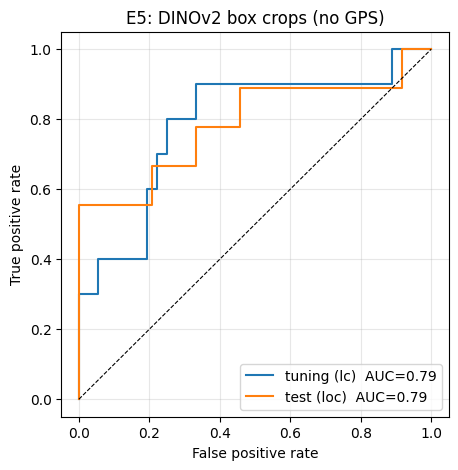

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

for name, ids in (("tuning lc", ids_t), ("test loc", ids_x)):
    n, h = recall_at_k(ids, R=1e9)
    print(name, "| بدون GPS: Recall@1 =", f"{h[1]}/{n}", "| Recall@5 =", f"{h[5]}/{n}")

plt.figure(figsize=(5, 5))
for name, rows in (("tuning (lc)", rows_t), ("test (loc)", rows_x)):
    y = [r[0] for r in rows]; s = [r[1] for r in rows]
    fpr, tpr, _ = roc_curve(y, s)
    plt.plot(fpr, tpr, label=f"{name}  AUC={roc_auc_score(y, s):.2f}")
plt.plot([0, 1], [0, 1], "k--", lw=0.8)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("E5: DINOv2 box crops (no GPS)")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("/kaggle/working/e5_roc.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
!pip -q install imagehash
import imagehash, torch
from torchvision import models, transforms
from sklearn.metrics import roc_auc_score

def get_crops(f):
    im = load_det(f); W, H = im.size
    out = []
    for d in dets_all[f]:
        mx, my = d["w"] * 0.10, d["h"] * 0.10
        box = (max(0, d["x"] - mx), max(0, d["y"] - my),
               min(W, d["x"] + d["w"] + mx), min(H, d["y"] + d["h"] + my))
        out.append((d["cls"], im.crop(box)))
    return out

crops_all = {f: get_crops(f) for f in info if dets_all[f]}

resnet = models.resnet18(weights="IMAGENET1K_V1")
resnet.fc = torch.nn.Identity()
resnet.eval()
tf = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(),
                         transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def fp_resnet(c):
    with torch.no_grad():
        v = resnet(tf(c).unsqueeze(0))[0]
    return (v / v.norm()).numpy()

def fp_phash(c):
    bits = imagehash.phash(c).hash.flatten().astype(float) * 2 - 1
    return bits / 8.0

CV_dino = CV
methods = {"DINOv2": None, "ResNet-18": fp_resnet, "pHash": fp_phash}

print("الطريقة | AUC tuning | AUC test | Recall@1 tuning | Recall@1 test | Recall@5 tuning | Recall@5 test  (بدون GPS)")
for name, fn in methods.items():
    CV = CV_dino if fn is None else {f: [(c, fn(im)) for c, im in cr] for f, cr in crops_all.items()}
    aucs, r1, r5 = [], [], []
    for prefix in ("lc", "loc"):
        ids, rows = make_rows(prefix)
        y = [r[0] for r in rows]; s = [r[1] for r in rows]
        n, h = recall_at_k(ids, R=1e9)
        aucs.append(round(roc_auc_score(y, s), 2))
        r1.append(f"{h[1]}/{n}"); r5.append(f"{h[5]}/{n}")
    print(f"{name:10s} | {aucs[0]} | {aucs[1]} | {r1[0]} | {r1[1]} | {r5[0]} | {r5[1]}")
CV = CV_dino

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 152MB/s]


الطريقة | AUC tuning | AUC test | Recall@1 tuning | Recall@1 test | Recall@5 tuning | Recall@5 test  (بدون GPS)
DINOv2     | 0.79 | 0.79 | 7/10 | 8/9 | 10/10 | 9/9
ResNet-18  | 0.81 | 0.81 | 8/10 | 7/9 | 10/10 | 9/9
pHash      | 0.74 | 0.66 | 4/10 | 6/9 | 10/10 | 9/9


In [12]:
THR, R = 0.80, 30

def classes(f):
    return sorted({c for c, _ in CV.get(f, [])})

print("=== مكررات فاتتنا (مع GPS) ===")
for name, rows in (("tuning", rows_t), ("test", rows_x)):
    for r in rows:
        if r[0] and not (r[1] >= THR and (r[2] is None or r[2] <= R)):
            a, b = by_id[r[3]]["a"], by_id[r[3]]["b"]
            print(name, r[3], f"sim={r[1]:.2f}", f"dist={r[2]}", classes(a), classes(b))

print("\n=== أخطاء بدون GPS (قلنا مكرر وهو لا) ===")
for name, rows in (("tuning", rows_t), ("test", rows_x)):
    for r in rows:
        if (not r[0]) and r[1] >= THR:
            d = "None" if r[2] is None else f"{r[2]:.0f}m"
            gps = "GPS يشيلها" if (r[2] is not None and r[2] > R) else "GPS ما يشيلها"
            print(name, r[3], "vs", r[4], f"sim={r[1]:.2f}", d, gps)

print("\n=== صور بدون صناديق YOLO ===")
none = [f for f in info if not dets_all[f]]
print(len(none), "من", len(info))
print(none)

=== مكررات فاتتنا (مع GPS) ===
tuning lc2 sim=0.54 dist=31.79607093389398 ['D40'] ['D40']
test loc26 sim=0.39 dist=1.5443739811114576 ['D40'] ['D40']

=== أخطاء بدون GPS (قلنا مكرر وهو لا) ===
tuning lc12 vs lc5 sim=0.89 1184m GPS يشيلها
tuning lc2 vs lc11 sim=0.86 1290m GPS يشيلها
tuning lc3 vs lc4 sim=0.91 26m GPS ما يشيلها
tuning lc3 vs lc5 sim=0.81 429m GPS يشيلها
tuning lc3 vs lc6 sim=0.82 429m GPS يشيلها
tuning lc4 vs lc3 sim=0.93 26m GPS ما يشيلها
tuning lc4 vs lc5 sim=0.84 403m GPS يشيلها
tuning lc5 vs lc3 sim=0.93 424m GPS يشيلها
tuning lc5 vs lc4 sim=0.89 399m GPS يشيلها
tuning lc5 vs lc6 sim=0.92 5m GPS ما يشيلها
tuning lc6 vs lc3 sim=0.92 427m GPS يشيلها
tuning lc6 vs lc4 sim=0.84 402m GPS يشيلها
tuning lc6 vs lc5 sim=0.82 3m GPS ما يشيلها
tuning lc7 vs lc11 sim=0.84 284m GPS يشيلها
tuning lc8 vs lc11 sim=0.85 313m GPS يشيلها
tuning lc8 vs lc5 sim=0.81 1554m GPS يشيلها
test loc18 vs loc19 sim=0.90 243m GPS يشيلها
test loc18 vs loc25 sim=0.88 4439m GPS يشيلها
test loc18 vs l

In [13]:
dups = [r for r in rows_t if r[0]]
non  = [r for r in rows_t if not r[0]]
print("tuning فقط، بدون GPS")
print("الحد | مكررات اكتشفناها | أخطاء")
for t in (0.80, 0.85, 0.88, 0.90, 0.92, 0.94, 0.96):
    c = sum(r[1] >= t for r in dups)
    w = sum(r[1] >= t for r in non)
    print(f"{t:.2f} | {c}/{len(dups)} | {w}/{len(non)}")

tuning فقط، بدون GPS
الحد | مكررات اكتشفناها | أخطاء
0.80 | 9/10 | 16/36
0.85 | 7/10 | 8/36
0.88 | 5/10 | 7/36
0.90 | 4/10 | 5/36
0.92 | 4/10 | 3/36
0.94 | 1/10 | 0/36
0.96 | 0/10 | 0/36


In [14]:
t = 0.92
dups = [r for r in rows_x if r[0]]
non  = [r for r in rows_x if not r[0]]
c = sum(r[1] >= t for r in dups)
w = sum(r[1] >= t for r in non)
print(f"test، بدون GPS، حد {t}")
print(f"مكررات اكتشفناها: {c}/{len(dups)}")
print(f"أخطاء: {w}/{len(non)}")

test، بدون GPS، حد 0.92
مكررات اكتشفناها: 4/9
أخطاء: 0/24
